# Read icgem 1.0 and icgem 2.0 gravity files with time variable components
*Author: R. Rietbroek Oct 2026 (r.rietbroek@utwente.nl)*

The [ICGEM format](https://icgem.gfz.de/docs/ICGEM-Format-2023.pdf) is often encountered on for example the [ICGEM service](https://icgem.gfz.de/home). However, some of the static models can also contain time variable components such as trends and (semi) annual amplitudes, possibly changing over varying time intervals.

This notebook, shows how one can read in these more complicated models and extract their time varying components from them.


## 1. Import the necessary modules

In [1]:
#Optionally enable autoreloading for development purposes. Note that this does not automagically reload the binary extensions
%load_ext autoreload
%autoreload 2
#also supress some warnings from pandas
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)


In [2]:
import shxarray
import xarray as xr
import numpy as np
import matplotlib.pyplot as mpl
from shxarray.earth.constants import c20_perm_tide

In [3]:
import inspect
import os

# adopt if needed ( the code below points to the testdata directory of the shxarray repository when installed in dev mode)
datadir=os.path.abspath(os.path.join(inspect.getfile(shxarray),'../../../tests/testdata'))
CNESicgem2file=os.path.join(datadir,"CNES_GRGS.RL05MF_u202601.gfc.gz")
GOCOicgemfile=os.path.join(datadir,"GOCO2025s.gfc.gz")

## 2. Read in all of the coefficients
This will use the icgem engine to read in the icgem files into a xarray dataset.

In [4]:
nmax=10 # note: for illustration, speed and memory purposes we supply the optional nmax to prevent loading all coefficients
dscnes=xr.open_dataset(CNESicgem2file,engine='icgem',nmax=nmax)
display(dscnes)

dsgoco=xr.open_dataset(GOCOicgemfile,engine='icgem',nmax=nmax)
display(dsgoco)


<xarray.Dataset> Size: 2MB
Dimensions:    (nm: 23869)
Coordinates:
  * ityp       (nm) object 191kB 'gfc' 'gfct' 'trnd' ... 'acos' 'asin' 'asin'
    n          (nm) int64 191kB ...
    m          (nm) int64 191kB ...
Dimensions without coordinates: nm
Data variables:
    cnm        (nm) float64 191kB ...
    sigcnm     (nm) float64 191kB ...
    t0         (nm) datetime64[ns] 191kB ...
    t1         (nm) datetime64[ns] 191kB ...
    period_yr  (nm) float64 191kB ...
Attributes:
    nmaxfile:   300
    nmax:       10
    format:     icgem2.0
    norm:       fully_normalized
    gm:         398600441500000.0
    re:         6378136.46
    modelname:  CNES_GRGS.RL05MF_u202601.shc

<xarray.Dataset> Size: 40kB
Dimensions:    (nm: 706)
Coordinates:
  * ityp       (nm) object 6kB 'gfc' 'gfc' 'gfc' 'gfc' ... 'acos' 'asin' 'asin'
    n          (nm) int64 6kB ...
    m          (nm) int64 6kB ...
Dimensions without coordinates: nm
Data variables:
    cnm        (nm) float64 6kB ...
    sigcnm     (nm) float64 6kB ...
    t0         (nm) datetime64[ns] 6kB ...
    period_yr  (nm) float64 6kB ...
Attributes:
    nmaxfile:   300
    nmax:       10
    format:     icgem1.0
    norm:       fully_normalized
    gm:         398600441500000.0
    re:         6378136.3
    modelname:  GOCO2025s

## 3. Extract a time series of the coefficients
The `dscnes` and `dsgoco` objects contain all the needed coefficients but these are not well organized and usable for e.g. the `synthesis` function. We therefore first want to sample the parametric model at given time epochs.


In [5]:
time=np.arange(np.datetime64("2000-01-15"), np.datetime64("2010-12-31"), np.timedelta64(7, "D"))

In [26]:
dscnestv=shxarray.io.icgem.sample_tv_grav(dscnes,time)
display(dscnestv)

<xarray.Dataset> Size: 561kB
Dimensions:  (nm: 121, time: 572)
Coordinates:
  * nm       (nm) object 968B MultiIndex
  * n        (nm) int64 968B 0 1 1 1 2 2 2 2 2 3 ... 10 10 10 10 10 10 10 10 10
  * m        (nm) int64 968B 0 -1 0 1 -2 -1 0 1 2 -3 -2 ... 1 2 3 4 5 6 7 8 9 10
  * time     (time) datetime64[s] 5kB 2000-01-15 2000-01-22 ... 2010-12-25
Data variables:
    cnm      (time, nm) float64 554kB 1.0 0.0 0.0 ... 1.254e-07 1.004e-07
Attributes:
    nmaxfile:   300
    nmax:       10
    format:     icgem2.0
    norm:       fully_normalized
    gm:         398600441500000.0
    re:         6378136.46
    modelname:  CNES_GRGS.RL05MF_u202601.shc

In [7]:
dsgocotv=shxarray.io.icgem.sample_tv_grav(dsgoco,time)
display(dsgocotv)

<xarray.Dataset> Size: 561kB
Dimensions:  (nm: 121, time: 572)
Coordinates:
  * nm       (nm) object 968B MultiIndex
  * n        (nm) int64 968B 0 1 1 1 2 2 2 2 2 3 ... 10 10 10 10 10 10 10 10 10
  * m        (nm) int64 968B 0 -1 0 1 -2 -1 0 1 2 -3 -2 ... 1 2 3 4 5 6 7 8 9 10
  * time     (time) datetime64[s] 5kB 2000-01-15 2000-01-22 ... 2010-12-25
Data variables:
    cnm      (time, nm) float64 554kB 1.0 0.0 0.0 ... 1.254e-07 1.004e-07
Attributes:
    nmaxfile:   300
    nmax:       10
    format:     icgem1.0
    norm:       fully_normalized
    gm:         398600441500000.0
    re:         6378136.3
    modelname:  GOCO2025s

## 4. Visualize J2 coefficient time series

Text(0.5, 1.0, 'C20 variation')

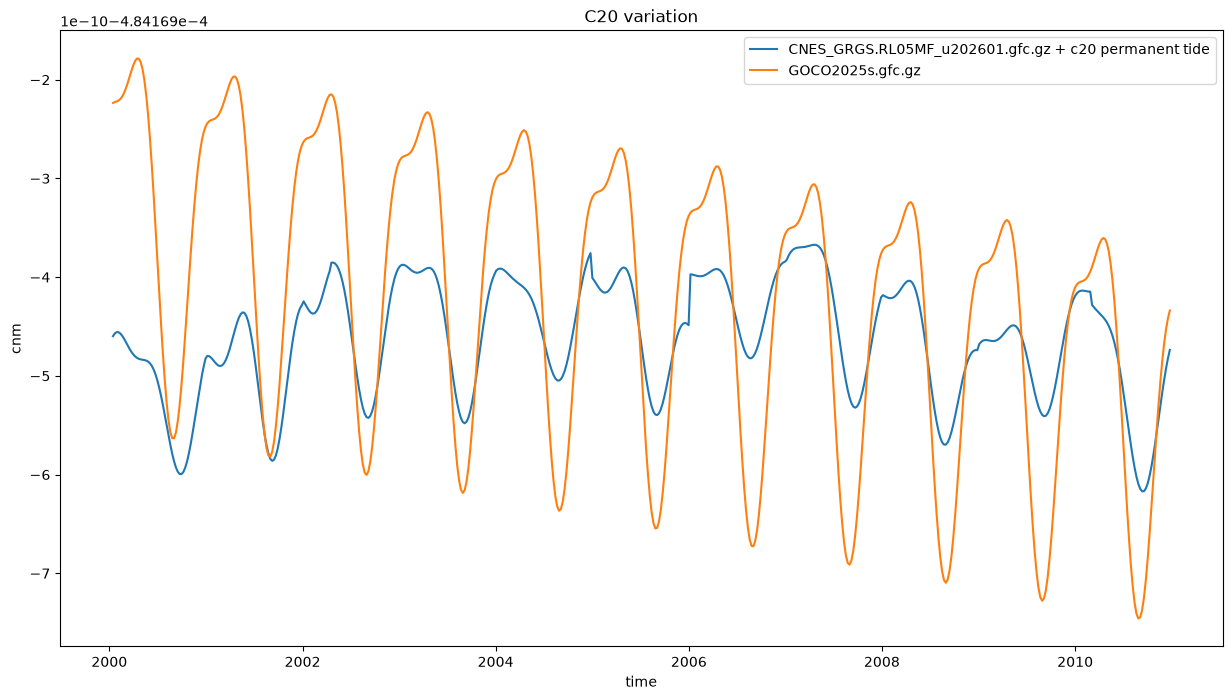

In [27]:
# Note setting truncate to False below keeps coefficients below the minimum degree of the filter to their original values
n=2
m=0
fig, axs = mpl.subplots(ncols=1,nrows=1,figsize=(15, 8))

dsc20cnes=dscnestv.sel(n=n,m=m)+c20_perm_tide
dsc20cnes.cnm.plot(ax=axs,label=os.path.basename(CNESicgem2file)+" + c20 permanent tide")
# dsc20cnes2=dscnestv2.sel(n=n,m=m)+c20_perm_tide
# dsc20cnes2.cnm.plot(ax=axs,label=os.path.basename(CNESicgem2file)+"v2 + c20 permanent tide")
# dsc20cnes3=dscnestv3.sel(n=n,m=m)+c20_perm_tide
# dsc20cnes3.cnm.plot(ax=axs,label=os.path.basename(CNESicgem2file)+"v3 + c20 permanent tide")
dsc20goco=dsgocotv.sel(n=n,m=m)
dsc20goco.cnm.plot(ax=axs,label=os.path.basename(GOCOicgemfile))
axs.legend()
axs.set_title('C20 variation')

## 5. Interpretation
The difference between the two sources comes, from what is included in the field (the GOCO model includes all non-tidal signals), and in the way the model is parameterized. A permanent tidal correction from `shxarray.earth.constants.c20_perm_tide` was applied to approximately bring the two in the same tidal system (zero-tide).